<a href="https://colab.research.google.com/github/Nihat0311/Machine-Learning/blob/main/KNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
! curl -L -o social-network-ads.zip\
  https://www.kaggle.com/api/v1/datasets/download/rakeshrau/social-network-ads

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100  3349  100  3349    0     0   6922      0 --:--:-- --:--:-- --:--:--     0


In [ ]:
! unzip social-network-ads.zip

Archive:  social-network-ads.zip
  inflating: Social_Network_Ads.csv  


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('Social_Network_Ads.csv')


In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline

In [ ]:
df

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0
...,...,...,...,...,...
395,15691863,Female,46,41000,1
396,15706071,Male,51,23000,1
397,15654296,Female,50,20000,1
398,15755018,Male,36,33000,0


In [ ]:
X=df.drop('Purchased',axis=1)
y=df['Purchased'].copy()

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.25,stratify=y,random_state=42
)

In [ ]:
num_features=X_train.select_dtypes(include=[np.number]).columns
cat_features=X_train.select_dtypes(exclude=[np.number]).columns

In [ ]:
num_pipeline=Pipeline([
    ('imputer',SimpleImputer(strategy='mean')),
    ('scaler',StandardScaler())
])

cat_pipeline=Pipeline([
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('encoder',OneHotEncoder(handle_unknown='ignore'))
])

transformer=ColumnTransformer([
    ('num',num_pipeline,num_features),
    ('cat',cat_pipeline,cat_features)
])

full_pipeline=Pipeline([
    ('transformer',transformer),
    ('model',KNeighborsClassifier(
        n_neighbors=5, # k
        metric='minkowski',
        p=2  #euclidien(p=2) ve ya manhattan(p=1) oldugunu bildirir
    ))
])

In [ ]:
full_pipeline.fit(X_train,y_train)

Pipeline(steps=[('transformer',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['User ID', 'Age', 'EstimatedSalary'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['Gender'], dtype='object'))])),
                ('model', KNeighborsClassifier())])

In [ ]:
full_pipeline.score(X_train,y_train)

0.9333333333333333

In [ ]:
full_pipeline.score(X_test,y_test)

0.88

In [ ]:
y_pred=full_pipeline.predict(X_test)

In [ ]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.91      0.91      0.91        64
           1       0.83      0.83      0.83        36

    accuracy                           0.88       100
   macro avg       0.87      0.87      0.87       100
weighted avg       0.88      0.88      0.88       100



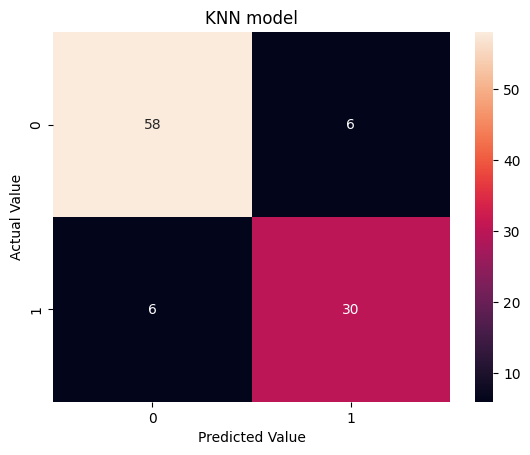

In [ ]:
cm=confusion_matrix(y_test,y_pred)
sns.heatmap(cm,annot=True,fmt='d')
plt.xlabel('Predicted Value')
plt.ylabel('Actual Value')
plt.title('KNN model')
plt.show()

In [ ]:
k_values=range(1,31,2)
best_k=None
best_score=-1
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

for k in k_values:
  pipe=Pipeline([
      ('transformer',transformer),
      ('knn',KNeighborsClassifier(
          n_neighbors=k,
          metric='minkowski',
          p=2
      ))
  ])
  scores=cross_val_score(pipe,X_train,y_train,cv=cv,scoring='accuracy')
  mean_score=scores.mean()
  if mean_score>best_score:
    best_score=mean_score
    best_k=k
print(f'best k: {best_k}')
print(f'best score is {best_score}')

best k: 5
best score is 0.9066666666666666
